In [1]:
import ollama

import utils
from prompts import BOUNDING_BOX_GENERATOR_SYSTEM_PROMPT
from utils import visualize_segmentation, generate_bounding_box_for_image
import json

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


First tests for vlm

In [2]:
client = ollama.Client(host='192.168.178.23')
system_prompt = ("Describe what is drawn on the photo")
# response = client.chat(
#     # model='qwen2.5vl:7b',
#     model='qwen3-vl:8b',
#     # model='minicpm-v:latest',
#     messages = [
#         {
#             'role': 'system',
#             'content': system_prompt,
#         },
#         {
#             'role': 'user',
#             'content': "Explain carefully what you see",
#             'images': ["test_images/test_image_1.jpg"]
#         }
#     ],
#     format='json',
#     options={'temperature':0.1}
# )
response = client.chat(
    model="qwen3-vl:8b",
    messages=[
        {
            "role": "user",
            "content": "Describe this image briefly in one sentence.",
            "images": ["test_images/test_image_1.jpg"]
        }
    ],
    options={
        "temperature": 0,
    }
)
content = response['message']['content']
content

'An AI-generated image depicts a whimsical, crispy fried food character with a bird-like face and white wings riding a horse in a vibrant grassy field, with colorful Angry Birds characters visible in the background.'

In [3]:
print("Content:", repr(response.message.content))
print("Thinking:", repr(response.message.thinking))
print("Done reason:", response.done_reason)
print("Eval count:", response.eval_count)

Content: 'An AI-generated image depicts a whimsical, crispy fried food character with a bird-like face and white wings riding a horse in a vibrant grassy field, with colorful Angry Birds characters visible in the background.'
Thinking: 'Got it, let\'s see. The image is from "The Angry Birds Movie," right? There\'s a character that looks like a fried chicken nugget with a bird face, riding a horse. Wait, no, actually, in the movie, there\'s a character called "The Chicken" or maybe it\'s a different one. Wait, the main character here is a square, crispy fried food character with a bird-like face, white wings, sitting on a horse. The background has a grassy field with flowers, a red bird (like the Angry Birds), and a green bird in the distance. The text says "AI-generated" at the bottom. So I need to describe it in one sentence.\n\nLet me check: the central figure is a cartoonish, crispy fried food character (like a chicken nugget) with a bird\'s face, white wings, riding a horse, in a g

Formalize in a function

In [4]:
from PIL import Image


def generate_bounding_box_for_image(
    ollama_host,
    image_path,
    user_prompt,
    model_name="qwen2.5vl:7b",
    temperature=0.1
):
    """
    Generates bounding box for the requested object/part on a given image.

    IMPORTANT:
    This function always returns bbox_2d in PIXEL coordinates:
    [x1, y1, x2, y2]

    - For qwen2.5vl: assumes model already returns pixel coordinates.
    - For qwen3-vl: converts normalized [0..1000] coordinates to pixels.

    Return JSON string:
    {
        "is_found": bool,
        "bbox_2d": [x1, y1, x2, y2] or null
    }
    """
    client = ollama.Client(host=ollama_host)
    system_prompt = BOUNDING_BOX_GENERATOR_SYSTEM_PROMPT

    response = client.chat(
        model=model_name,
        messages=[
            {
                'role': 'system',
                'content': system_prompt,
            },
            {
                'role': 'user',
                'content': f"{user_prompt}",
                'images': [image_path]
            }
        ],
        format='json',
        options={
            'temperature': temperature,
            'num_predict': 1024
        }
    )

    content = response['message']['content']

    # Handle empty response safely
    if content is None or content.strip() == "":
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    # Sometimes models may return whitespace or malformed formatting
    content = content.strip()

    try:
        data = json.loads(content)
    except json.JSONDecodeError:
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    # Basic validation
    if not isinstance(data, dict):
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    is_found = data.get("is_found", False)
    bbox = data.get("bbox_2d", None)

    if (not is_found) or bbox is None:
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    if not isinstance(bbox, list) or len(bbox) != 4:
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    # Convert bbox values to numbers
    try:
        bbox = [float(v) for v in bbox]
    except Exception:
        return json.dumps({
            "is_found": False,
            "bbox_2d": None
        })

    # If using Qwen3-VL, convert normalized [0..1000] to pixel coordinates
    if "qwen3" in model_name.lower():
        image = Image.open(image_path)
        width, height = image.size

        x1 = round(bbox[0] * width / 1000)
        y1 = round(bbox[1] * height / 1000)
        x2 = round(bbox[2] * width / 1000)
        y2 = round(bbox[3] * height / 1000)
    else:
        # Qwen2.5-VL path: assume output is already pixel coordinates
        x1, y1, x2, y2 = [round(v) for v in bbox]

    # Clamp to image bounds for safety
    image = Image.open(image_path)
    width, height = image.size

    x1 = max(0, min(x1, width - 1))
    y1 = max(0, min(y1, height - 1))
    x2 = max(0, min(x2, width - 1))
    y2 = max(0, min(y2, height - 1))

    # Make sure bbox is ordered correctly
    if x1 > x2:
        x1, x2 = x2, x1
    if y1 > y2:
        y1, y2 = y2, y1

    return json.dumps({
        "is_found": True,
        "bbox_2d": [x1, y1, x2, y2]
    })

Verification of the performance on the actual bounding box generation task

{"is_found": true, "bbox_2d": [324, 414, 510, 500]}
Image size (H, W, C): (1280, 718, 3)


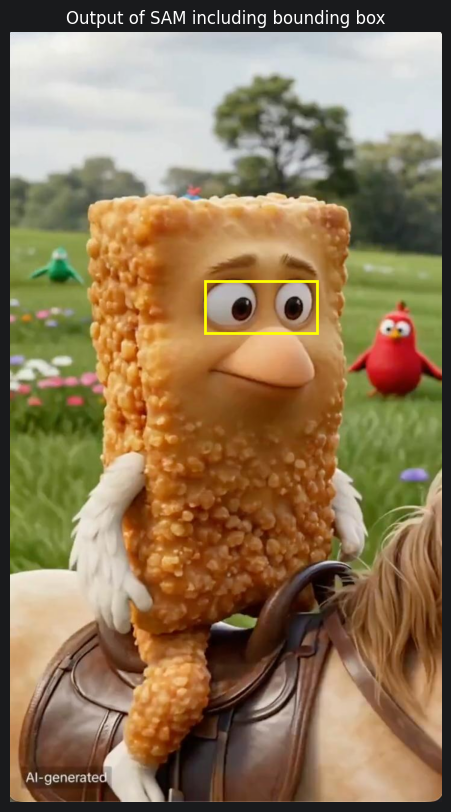

In [5]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "two eyes"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{"is_found": true, "bbox_2d": [568, 446, 717, 614]}
Image size (H, W, C): (1280, 718, 3)


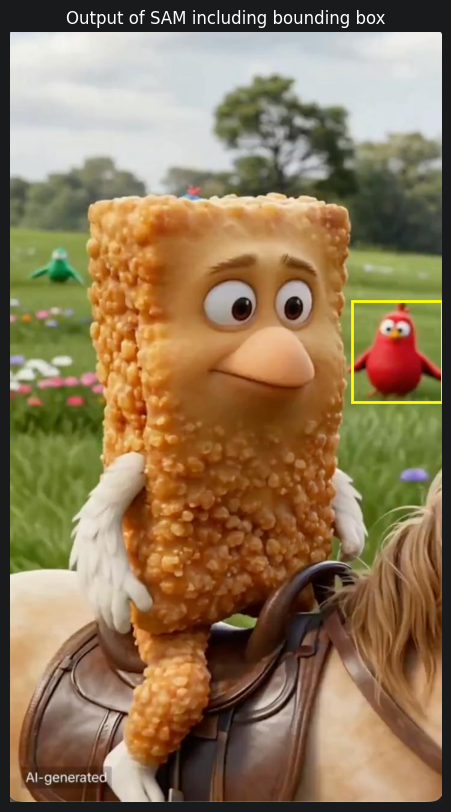

In [6]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "red chicken"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

Image size (H, W, C): (1280, 718, 3)


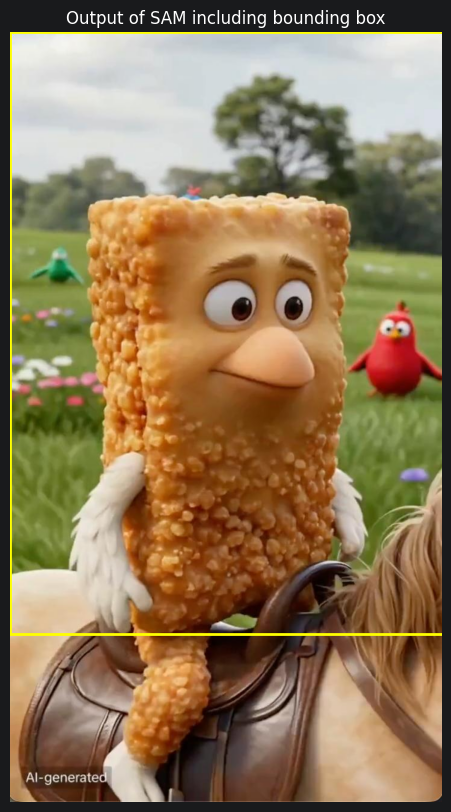

In [7]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "airplane"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
is_found = data['is_found']
if not is_found:
    visualize_segmentation(image_path= image_path ,mask=None,x1= 0,y1= 0,x2= 1000,y2= 1000)
else:
    four_coordinates = data['bbox_2d']
    x1= four_coordinates[0]
    y1= four_coordinates[1]
    x2= four_coordinates[2]
    y2= four_coordinates[3]
    print(json_output)
    visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{"is_found": true, "bbox_2d": [0, 463, 157, 634]}
Image size (H, W, C): (1280, 718, 3)


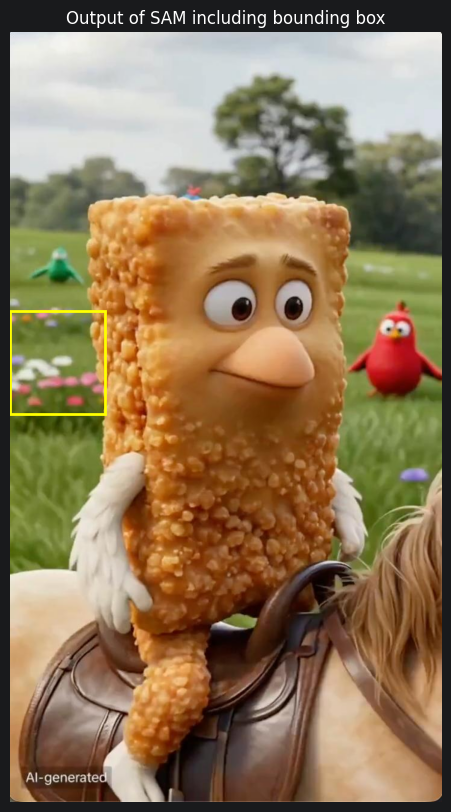

In [8]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "white flowers"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{'is_found': True, 'bbox_2d': [788, 416, 838, 590]}
Image size (H, W, C): (1008, 1008, 3)


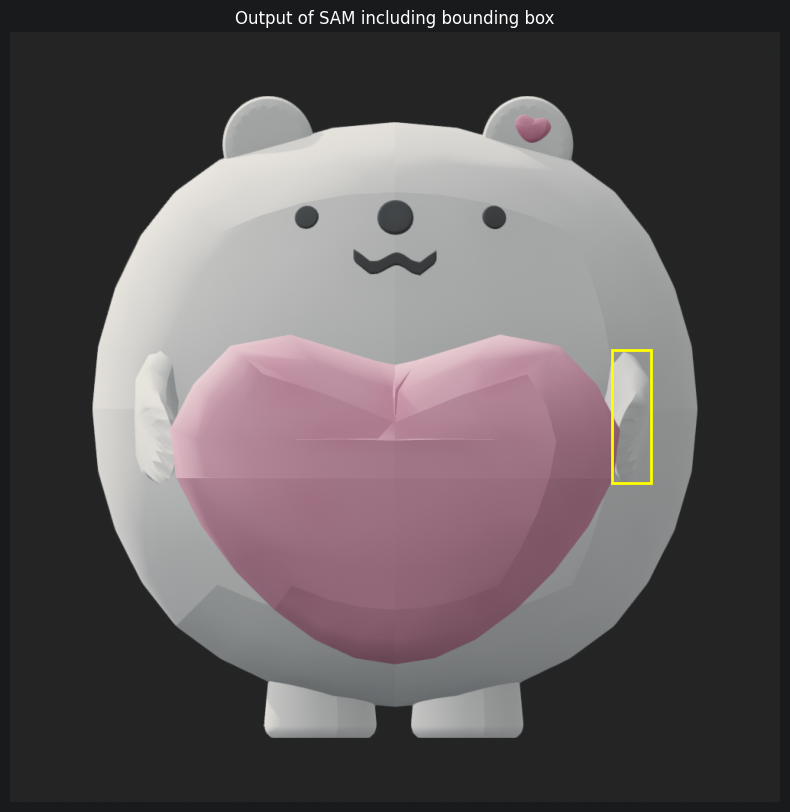

In [22]:

image_path = "test_images/test_image_2.png"
user_prompt = "hand of character"

json_output = generate_bounding_box_for_image(
    '192.168.178.23',
    image_path,
    user_prompt
)

data = json.loads(json_output)
print(data)

if data["is_found"] and data["bbox_2d"] is not None:
    x1, y1, x2, y2 = data["bbox_2d"]

    visualize_segmentation(
        image_path=image_path,
        mask=None,
        x1=x1,
        y1=y1,
        x2=x2,
        y2=y2
    )
else:
    print(f"Object '{user_prompt}' was not detected in this view.")


{"is_found": true, "bbox_2d": [395, 745, 511, 816]}
Image size (H, W, C): (1008, 1008, 3)


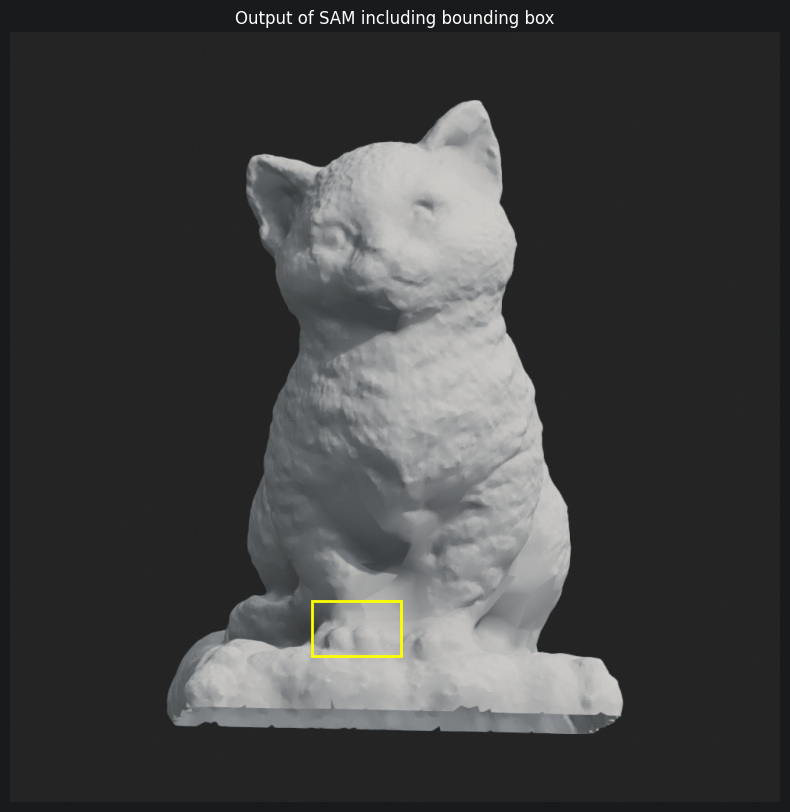

In [10]:
image_path = "test_images/test_image_3.png"
user_prompt = "paw"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
is_found = data['is_found']
if not is_found:
    visualize_segmentation(image_path= image_path ,mask=None,x1= 0,y1= 0,x2= 1000,y2= 1000)
else:
    four_coordinates = data['bbox_2d']
    x1= four_coordinates[0]
    y1= four_coordinates[1]
    x2= four_coordinates[2]
    y2= four_coordinates[3]
    print(json_output)
    visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)